In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_clean = pd.read_csv(
    "C:/Users/main/Desktop/Projects/Customer Churn Prediction System/data/cleaned_customer_churn.csv"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())


Dataset loaded successfully!
Dataset shape: (7043, 21)
Missing values: 0


In [3]:

# Separate input features and target
X = df_clean.drop(columns=["Churn", "customerID"])
y = df_clean["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Target values:", sorted(y.unique()))


Features shape: (7043, 19)
Target shape: (7043,)
Target values: [np.int64(0), np.int64(1)]


In [4]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))


Training features: (5634, 19)
Testing features: (1409, 19)

Training target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [5]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Identify numeric and categorical columns
numeric_features = X_train.select_dtypes(
    include=["int64", "float64", "number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category", "string"]
).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

# Prepare numeric columns
numeric_transformer = Pipeline(steps=[
    ("scaler", StandardScaler())
])

# Prepare categorical columns
categorical_transformer = Pipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("\nPreprocessor created successfully!")


Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Preprocessor created successfully!


In [6]:

from sklearn.linear_model import LogisticRegression

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")


Model trained successfully!


Accuracy: 0.8055
ROC-AUC: 0.8421

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



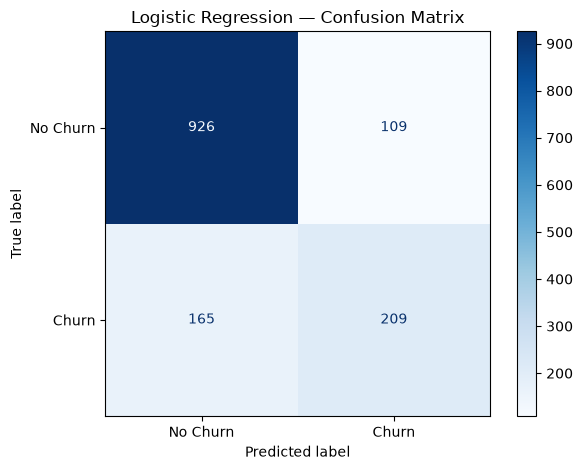

In [7]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay
)

# Predict churn labels and probabilities
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"]
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)

plt.title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()


In [8]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 1.4 MB/s eta 0:00:35
    --------------------------------------- 0.8/48.9 MB 1.4 MB/s eta 0:00:35
    --------------------------------------- 1.0/48.9 MB 1.5 MB/s eta 0:00:34
   - -------------------------------------- 1.6/48.9 MB 1.4 MB/s eta 0:00:34
   - -------------------------------------- 1.8/48.9 MB 1.4 MB

In [9]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    ))
])

xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


XGBoost Results
--------------------
Accuracy: 0.7991
Precision: 0.6522
Recall: 0.5214
F1-score: 0.5795
ROC-AUC: 0.8426

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87      1035
       Churn       0.65      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



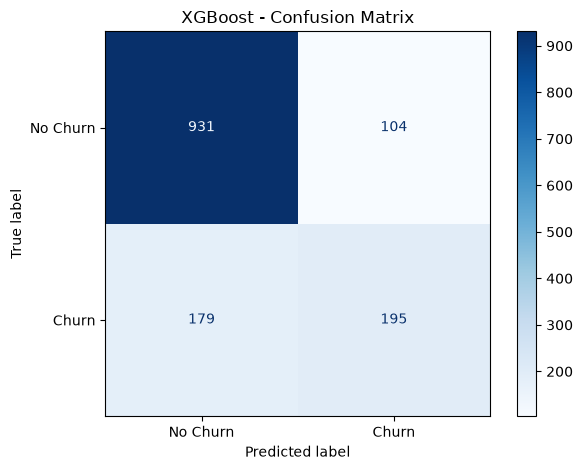

In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

xgb_pred = xgb_model.predict(X_test)
xgb_proba = xgb_model.predict_proba(X_test)[:, 1]

print("XGBoost Results")
print("--------------------")
print("Accuracy:", round(accuracy_score(y_test, xgb_pred), 4))
print("Precision:", round(precision_score(y_test, xgb_pred), 4))
print("Recall:", round(recall_score(y_test, xgb_pred), 4))
print("F1-score:", round(f1_score(y_test, xgb_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, xgb_proba), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    xgb_pred,
    target_names=["No Churn", "Churn"]
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_pred,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)

plt.title("XGBoost - Confusion Matrix")
plt.tight_layout()
plt.show()

In [11]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "XGBoost"],
    "Accuracy": [
        accuracy_score(y_test, model.predict(X_test)),
        accuracy_score(y_test, xgb_pred)
    ],
    "Precision": [
        precision_score(y_test, model.predict(X_test)),
        precision_score(y_test, xgb_pred)
    ],
    "Recall": [
        recall_score(y_test, model.predict(X_test)),
        recall_score(y_test, xgb_pred)
    ],
    "F1-Score": [
        f1_score(y_test, model.predict(X_test)),
        f1_score(y_test, xgb_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_test, xgb_proba)
    ]
})

comparison = comparison.round(4)
comparison

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8421
1,XGBoost,0.7991,0.6522,0.5214,0.5795,0.8426


In [12]:
%pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   --------------------------- ------------ 524.3/751.9 kB 2.6 MB/s eta 0:00:01
   --------------------------- ------------ 524.3/751.9 kB 2.6 MB/s eta 0:00:01
   --------------------------- ------------ 524.3/751.9 kB 2.6 MB/s eta 0:00:01
   --------------------------- ------------ 524.3/751.9 kB 2.6 MB/s eta 0:00:01
   --------------------------- ------------ 524.3/751.9 kB 2.6 MB/s eta 0:00:01
   ---------------------------------------- 751.9/751.9 kB 399.0 kB/s  0:00:01

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/

In [1]:
import shap
import pandas as pd
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


In [2]:
# Get the fitted preprocessing pipeline
preprocessor_fitted = xgb_model.named_steps["preprocessor"]

# Transform the test dataset
X_test_transformed = preprocessor_fitted.transform(X_test)

# Get the feature names after one-hot encoding
feature_names = preprocessor_fitted.get_feature_names_out()

# Convert transformed data into a DataFrame
X_test_transformed_df = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index
)

print("Transformed test data shape:", X_test_transformed_df.shape)
print("Number of feature names:", len(feature_names))

NameError: name 'xgb_model' is not defined

In [3]:
print("xgb_model" in globals())

False


In [6]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

# Load your cleaned dataset
df_clean = pd.read_csv(
    "C:/Users/main/Desktop/Projects/Customer Churn Prediction System/data/cleaned_customer_churn.csv"
)

# Separate features and target
X = df_clean.drop(columns=["Churn", "customerID"])
y = df_clean["Churn"].map({"No": 0, "Yes": 1})

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Dataset loaded and split successfully!")
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Dataset loaded and split successfully!
Training data: (5634, 19)
Testing data: (1409, 19)


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Process numerical features
numeric_transformer = Pipeline(steps=[
    ("scaler", StandardScaler())
])

# Process categorical features
categorical_transformer = Pipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing methods
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessor created successfully!")
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Preprocessor created successfully!
Numerical features: 4
Categorical features: 15


In [8]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    ))
])

xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [9]:
import shap

preprocessor_fitted = xgb_model.named_steps["preprocessor"]

X_test_transformed = preprocessor_fitted.transform(X_test)

feature_names = preprocessor_fitted.get_feature_names_out()

X_test_transformed_df = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index
)

print("Transformed test data shape:", X_test_transformed_df.shape)
print("Number of feature names:", len(feature_names))

Transformed test data shape: (1409, 45)
Number of feature names: 45


In [10]:
import shap

# Get the trained XGBoost classifier
xgb_classifier = xgb_model.named_steps["classifier"]

# Create the SHAP explainer
explainer = shap.TreeExplainer(xgb_classifier)

# Calculate SHAP values
shap_values = explainer(X_test_transformed_df)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


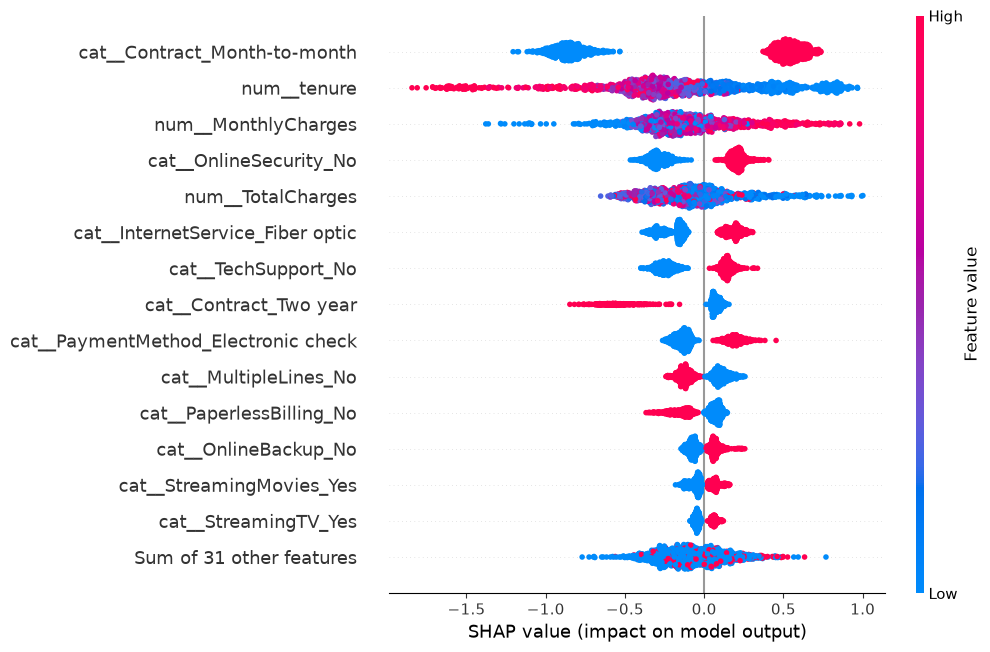

In [11]:
shap.plots.beeswarm(shap_values, max_display=15)

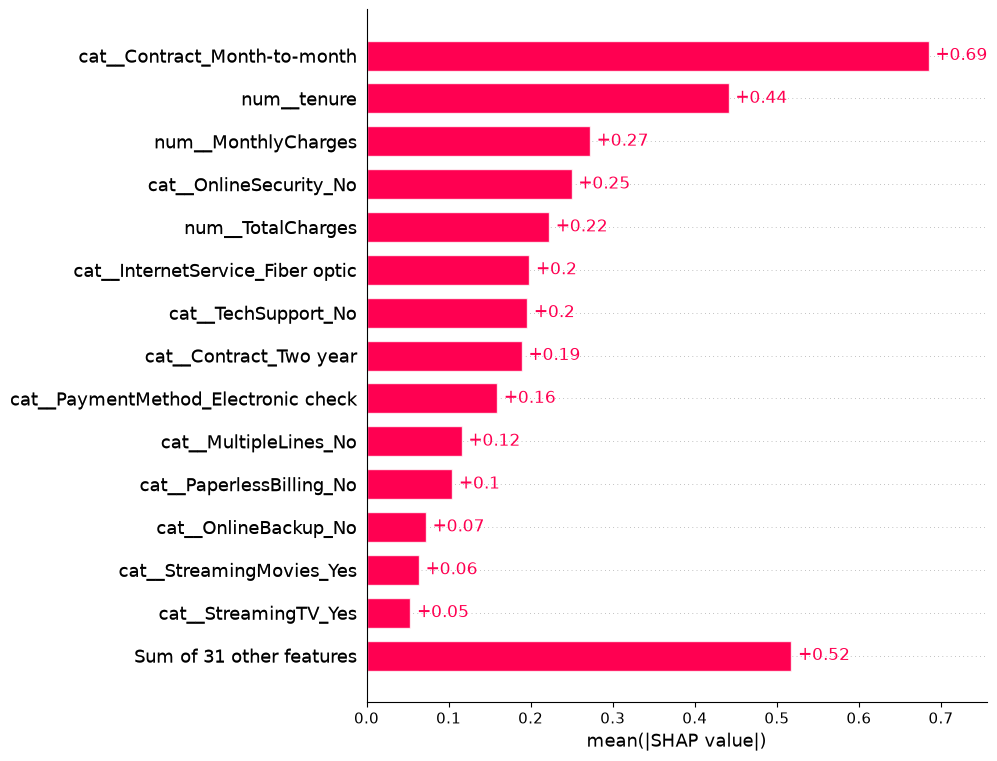

In [12]:
shap.plots.bar(shap_values, max_display=15)

Actual churn: No
Predicted churn: No
Churn probability: 1.04 %


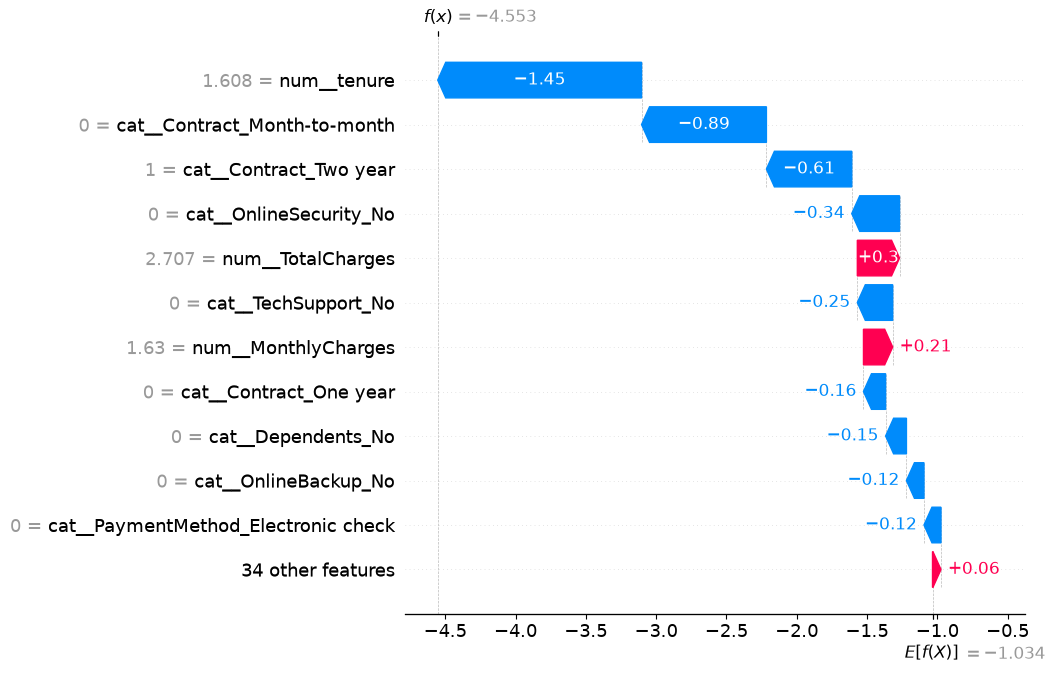

In [13]:
customer_index = 0

# Actual outcome
actual = y_test.iloc[customer_index]

# Model prediction
predicted = xgb_model.predict(X_test.iloc[[customer_index]])[0]

# Probability of churn
probability = xgb_model.predict_proba(
    X_test.iloc[[customer_index]]
)[0, 1]

print("Actual churn:", "Yes" if actual == 1 else "No")
print("Predicted churn:", "Yes" if predicted == 1 else "No")
print("Churn probability:", round(probability * 100, 2), "%")

# Display explanation
shap.plots.waterfall(
    shap_values[customer_index],
    max_display=12
)

In [14]:
import joblib
from pathlib import Path

# Define the model output folder
model_dir = Path(
    "C:/Users/main/Desktop/Projects/Customer Churn Prediction System/models"
)

# Create the folder if it doesn't exist
model_dir.mkdir(parents=True, exist_ok=True)

# Save the complete pipeline
model_path = model_dir / "xgboost_churn_pipeline.pkl"

joblib.dump(xgb_model, model_path)

print("Model saved successfully!")
print("Saved at:", model_path)

Model saved successfully!
Saved at: C:\Users\main\Desktop\Projects\Customer Churn Prediction System\models\xgboost_churn_pipeline.pkl


In [15]:
import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: C:\Users\main\anaconda3-pbe\envs\anaconda-2026.07\python.exe
Python version: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]


In [16]:
import sys
print(sys.executable)

C:\Users\main\anaconda3-pbe\envs\anaconda-2026.07\python.exe


In [ ]:
#Go to cmd and goto project folder:
# cd "C:\Users\main\Desktop\Projects\Customer Churn Prediction System"

#Copy this in cmd
#C:\Users\main\anaconda3-pbe\envs\anaconda-2026.07\python.exe -m streamlit run app.py
